# 练习 1：多变量线性回归

**目标：用建筑的 4 个特征预测供暖负荷，自己完成训练过程。**

本次使用 NumPy 和 Matplotlib；scikit-learn 留到下一次练习。这里没有算法实现或答案。

数据来自 [UCI Energy Efficiency](https://archive.ics.uci.edu/dataset/242/energy+efficiency)，共 768 条建筑能耗模拟记录，已检查无缺失值、非数值或无穷值。已划分为 614 条训练数据和 154 条测试数据，尚未标准化。

| 列 | 名称 | 含义 |
|---|---|---|
| 1 | wall_area | 墙面面积 |
| 2 | roof_area | 屋顶面积 |
| 3 | overall_height | 建筑总高度 |
| 4 | glazing_area | 玻璃面积比例，例如 0.25 表示 25% |
| 5 | heating_load | 供暖负荷，预测目标 |

原始数值未修改。数据来源、处理记录和许可详见同目录的 `数据说明.txt`。


## 1. 读取数据

读取部分已经准备好，后面的代码由你完成。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

train_data = np.loadtxt("train.txt")
test_data = np.loadtxt("test.txt")

X_train = train_data[:, :4]
y_train = train_data[:, 4]
X_test = test_data[:, :4]
y_test = test_data[:, 4]

print("训练集：", X_train.shape, y_train.shape)
print("测试集：", X_test.shape, y_test.shape)


训练集： (614, 4) (614,)
测试集： (154, 4) (154,)


## 2. 特征标准化

自行完成。标准化参数只能从训练集计算。

In [2]:
def z_score_standard(X):
    mu = X.mean(axis=0)
    std = X.std(axis=0)
    return (X-mu)/std
        

## 3. 预测与成本函数

自行实现多变量线性回归的预测与成本计算。

In [3]:
def compute_cost(X,y,W,b):
    m = len(y)
    total_cost = 0
    for i in range(m):
        total_cost += (np.dot(X[i],W)+b-y[i])*(np.dot(X[i],W)+b-y[i])

    total_cost = total_cost / (2*m)
    return total_cost


## 4. 梯度计算与梯度下降

自行实现批量梯度下降。

In [4]:
def compute_gradient(X,y,W,b):
    
    m = len(y)
    n = len(X[0])

    dj_dw = np.zeros(n,dtype=float)
    dj_db = 0
    for i in range(m):
        error = np.dot(X[i],W)+b-y[i]
        for j in range(n):
            dj_dw[j] += (error)*X[i][j]
        dj_db += error
    dj_dw = dj_dw / m
    dj_db = dj_db / m
    return dj_dw,dj_db


    

In [5]:
def gradient_descend(X,y,W,b,alpha,iterations,compute_cost_function,compute_gradient_function,standard_function):
    X = z_score_standard(X)
    J_his = [compute_cost_function(X,y,W,b)]
    for itera in range(iterations):
        dj_dw,dj_db = compute_gradient_function(X,y,W,b)
        W = W - alpha * dj_dw
        b = b - alpha * dj_db
        J_his.append(compute_cost_function(X,y,W,b))
        if itera % (iterations/10) == 0:
            print(f'current cost is :{compute_cost_function(X,y,W,b):.6f}')

    return np.array(W),b,J_his
            
        

## 5. 训练与成本曲线

选择学习率和迭代次数，训练模型并绘制训练成本曲线。

In [6]:
np.random.seed(42)
n = len(X_train[0])
W_init,b_init = np.zeros(X_train.shape[1]),0.0

In [7]:
print(f'W:{W_init},b:{b_init}')

W:[0. 0. 0. 0.],b:0.0


In [8]:
print(f'???')
print(f'the initial cost is :{compute_cost(X_train,y_train,W_init,b_init)}')

???
the initial cost is :296.462616332247


In [9]:
W,b,J_his = gradient_descend(X_train,y_train,W_init,b_init,0.06,500,compute_cost,compute_gradient,z_score_standard)

current cost is :257.695463
current cost is :5.824142
current cost is :5.254707
current cost is :5.155637
current cost is :5.072250
current cost is :5.001401
current cost is :4.941202
current cost is :4.890052
current cost is :4.846591
current cost is :4.809664


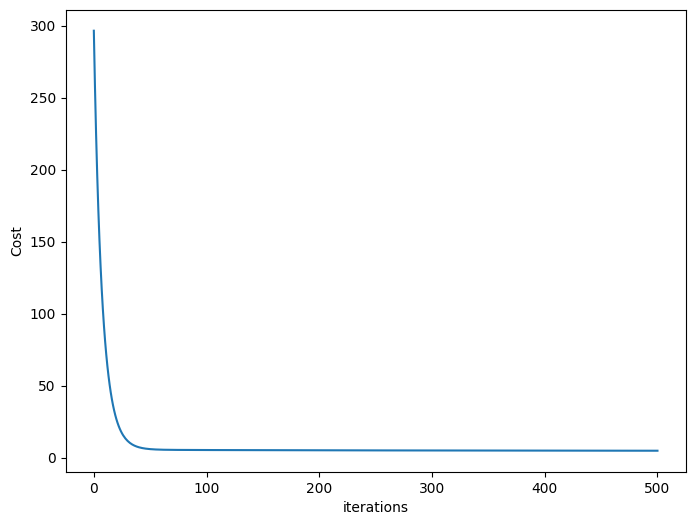

In [10]:
import matplotlib.pyplot as plt
iterations = np.arange(0,len(J_his))
plt.figure(figsize=(8,6))
plt.plot(iterations,J_his)
plt.xlabel('iterations',fontsize=10)
plt.ylabel('Cost',fontsize=10)
plt.show()

## 6. 测试集评估

计算测试集成本，展示前 5 个样本的预测值和真实值。测试集只用于最后评估。

In [18]:
mu = X_train.mean(axis=0)
std = X_train.std(axis=0)
normalized = (X_test-mu) / std
J_test = compute_cost(normalized,y_test,W,b)
inputs = normalized[:5]

real = y_test[:5]
predict = inputs @ (W.T) + b
print(f'J_test={J_test}')
print(f'real:{real}')
print(f'predict:{predict}')

J_test=4.277968516572422
real:[15.23  6.85 28.17 12.33 36.45]
predict:[17.43803005  8.00511373 30.16124222 11.85325551 36.20545685]


## 7. 我的记录

记录使用的学习率、迭代次数和观察到的现象。

在这里写你的记录。